# YouTube India: trending categories, engagement and repeat appearances

This project uses the India trending file. A row is a video’s appearance on one trending date, so a video can appear many times. Category prevalence, last-observed engagement, first-observed delay and persistence are analysed with separate video-level tables.

## Data and scope

Source: [youtube-new](https://www.kaggle.com/datasets/datasnaek/youtube-new). This report uses the uploaded snapshot, not live data.

`video_id` identifies a video, and `trending_date` is its snapshot date in YY.DD.MM format. `publish_time` is the upload timestamp. `category_id` maps to names in `IN_category_id.json`. `views`, `likes`, `dislikes` and `comment_count` are cumulative counters at that snapshot. `comments_disabled`, `ratings_disabled` and `video_error_or_removed` flag limitations. `title`, `channel_title`, `tags`, `description` and `thumbnail_link` are metadata. Counts are not daily increments.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("INvideos.csv"))
print(f"Raw snapshots: {len(raw):,}; columns: {raw.shape[1]}")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.drop(columns=["description","tags"]).head())
display(raw.isna().sum().to_frame("missing"))

Raw snapshots: 37,352; columns: 16


,video_id,trending_date,title,channel_title,category_id,publish_time,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False


,missing
video_id,0
trending_date,0
title,0
channel_title,0
category_id,0
publish_time,0
tags,0
views,0
likes,0
dislikes,0



Trending dates use an unusual order, so they are parsed with an explicit format. Exact repeated rows are removed; videos with several dates are retained. For engagement, the last recorded snapshot per video is used. For delay, the first recorded appearance is used. `map()` adds category names. Missing descriptions do not remove usable numeric observations. Counters below zero are invalid and become missing. The sentinel video ID `#NAME?`, if present, is excluded because it cannot identify a real video.

Repeated video-date keys after exact deduplication: 375
Usable snapshots: 32,272; distinct videos: 16,306; dates: 2017-11-14 to 2018-06-14


,count,mean,std,min,25%,50%,75%,max
views,"16,306.000","683,300.016","2,362,923.693","4,024.000","88,591.000","205,479.000","528,905.750","125,432,237.000"
likes,"16,306.000","14,435.020","66,870.427",0.000,561.000,"1,743.500","6,459.000","2,912,710.000"
dislikes,"16,306.000",956.904,"12,643.418",0.000,69.000,194.000,591.000,"1,545,017.000"
comment_count,"16,306.000","1,481.108","10,408.472",0.000,47.000,195.000,700.000,"807,558.000"


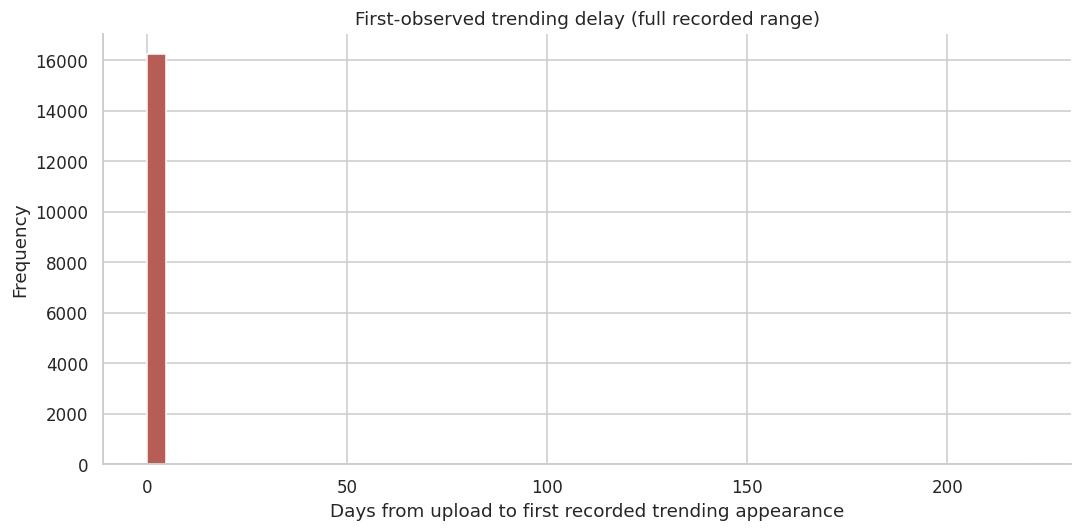

In [3]:
df = raw.drop_duplicates().copy()
df = df[df.video_id.notna() & ~df.video_id.eq("#NAME?")].copy()
df["trend_date"] = pd.to_datetime(df.trending_date,format="%y.%d.%m",errors="coerce")
df["published"] = pd.to_datetime(df.publish_time,utc=True,errors="coerce")
for col in ["views","likes","dislikes","comment_count"]:
    df[col] = pd.to_numeric(df[col],errors="coerce")
    df.loc[df[col]<0,col] = np.nan
for col in ["comments_disabled","ratings_disabled","video_error_or_removed"]:
    df[col] = df[col].astype(str).str.lower().map({"true":True,"false":False})
with open(data_path("IN_category_id.json"),encoding="utf-8") as handle:
    category_map = {int(x["id"]):x["snippet"]["title"] for x in json.load(handle)["items"]}
df["category"] = df.category_id.map(category_map).fillna("Unmapped")
print(f"Repeated video-date keys after exact deduplication: {df.duplicated(['video_id','trend_date']).sum():,}")
snapshots = df.dropna(subset=["trend_date"]).sort_values(["trend_date","views"]).drop_duplicates(["video_id","trend_date"],keep="last")
latest = snapshots.drop_duplicates("video_id",keep="last").copy()
first = snapshots.drop_duplicates("video_id",keep="first").copy()
first["delay_days"] = (first.trend_date-first.published.dt.tz_convert(None).dt.normalize()).dt.days
print(f"Usable snapshots: {len(snapshots):,}; distinct videos: {len(latest):,}; dates: {snapshots.trend_date.min().date()} to {snapshots.trend_date.max().date()}")
display(latest[["views","likes","dislikes","comment_count"]].describe().T)
first.delay_days.dropna().plot.hist(bins=45,color="#b85c56")
plt.xlabel("Days from upload to first recorded trending appearance"); plt.title("First-observed trending delay (full recorded range)")
plt.tight_layout(); plt.show()

## 1. Which categories contain the most distinct trending videos?

Each video is counted once using its latest supplied category. This avoids treating a video that trends for ten days as ten different videos. Shares refer to videos captured in this historical trending sample, not all uploaded videos.

,distinct_videos,share_pct
category,,
Entertainment,7547,46.284
News & Politics,2505,15.362
People & Blogs,1232,7.556
Music,1213,7.439
Comedy,1114,6.832
Education,797,4.888
Film & Animation,522,3.201
Howto & Style,478,2.931
Sports,347,2.128


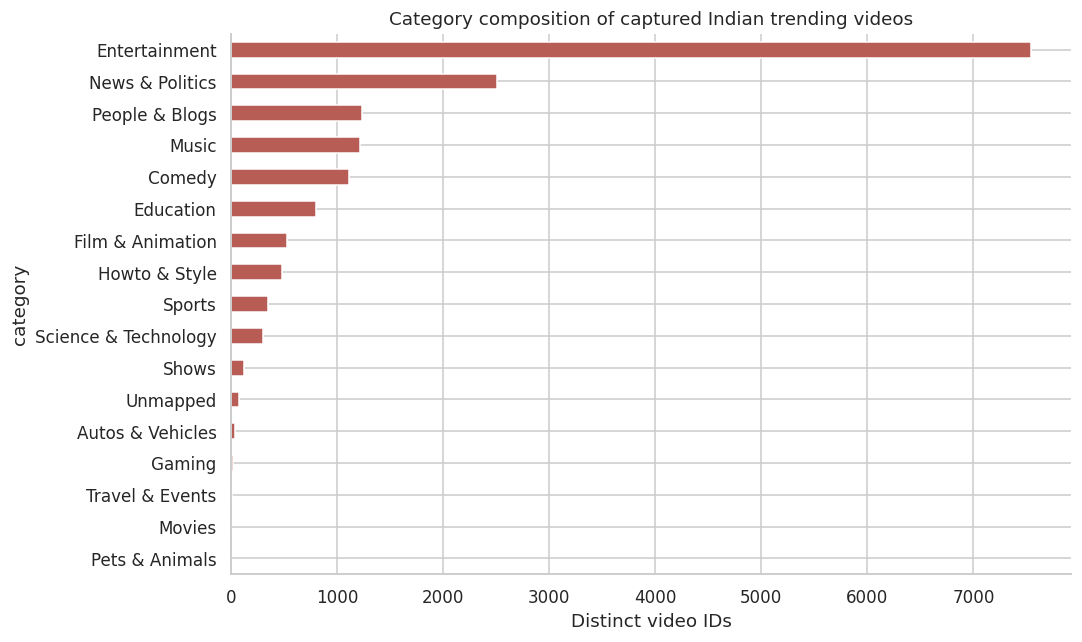

In [4]:
categories = latest.category.value_counts()
display(pd.DataFrame({"distinct_videos":categories,"share_pct":categories/len(latest)*100}))
categories.sort_values().plot.barh(color="#b85c56",figsize=(10,6))
plt.xlabel("Distinct video IDs"); plt.title("Category composition of captured Indian trending videos")
plt.tight_layout(); plt.show()

**Answer.** Entertainment is the largest category with 7,547 distinct videos (46.3%). These counts describe captured trending videos, so they cannot estimate a category’s chance of trending without knowing how many videos were uploaded.

## 2. Which categories have the highest median last-observed views?

Only categories with at least 30 videos with recorded views are compared. `median()` limits the influence of a few very large videos. Last-observed counters are not lifetime totals and videos are observed at different ages.

,count,median,mean
category,,,
Shows,121,"621,739.000","649,225.537"
Music,1213,"552,724.000","2,017,880.624"
Sports,347,"503,864.000","1,379,353.406"
Film & Animation,522,"491,068.000","1,795,491.678"
Comedy,1114,"353,683.000","717,054.811"
Science & Technology,300,"253,736.000","664,622.347"
Howto & Style,478,"234,001.000","826,816.933"
Entertainment,7547,"201,710.000","574,766.277"
People & Blogs,1232,"177,213.500","450,423.363"


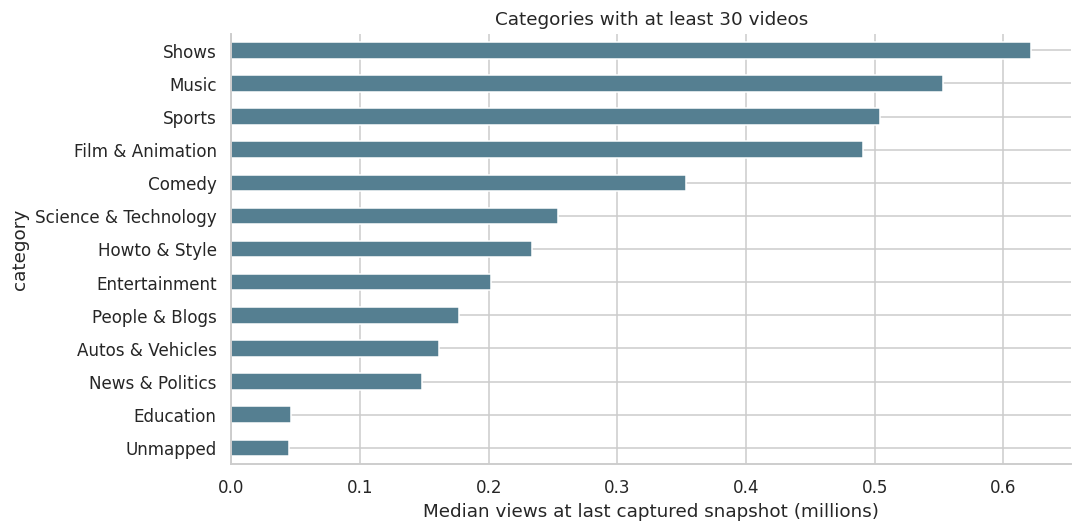

In [5]:
category_views = latest.groupby("category").views.agg(["count","median","mean"])
eligible = category_views[category_views["count"]>=30].sort_values("median",ascending=False)
display(eligible)
eligible["median"].div(1e6).sort_values().plot.barh(color="#557f91")
plt.xlabel("Median views at last captured snapshot (millions)")
plt.title("Categories with at least 30 videos"); plt.tight_layout(); plt.show()

**Answer.** Shows has the highest median last-observed views among eligible categories (621,739). Category comparisons may reflect video age, channel mix and the length of each video’s captured trending run.

## 3. Are larger view counts associated with more likes?

Videos with ratings disabled, missing counters or zero views are excluded. Spearman correlation describes the association between cumulative counters. Likes per 1,000 views are shown separately so that engagement is not reduced to audience size.

,count,median
category,,
Pets & Animals,1,74.799
Science & Technology,299,62.945
Education,700,51.414
Unmapped,48,47.543
Comedy,1114,38.983
Gaming,20,32.781
Music,1210,17.926
Travel & Events,4,17.707
Film & Animation,520,14.978


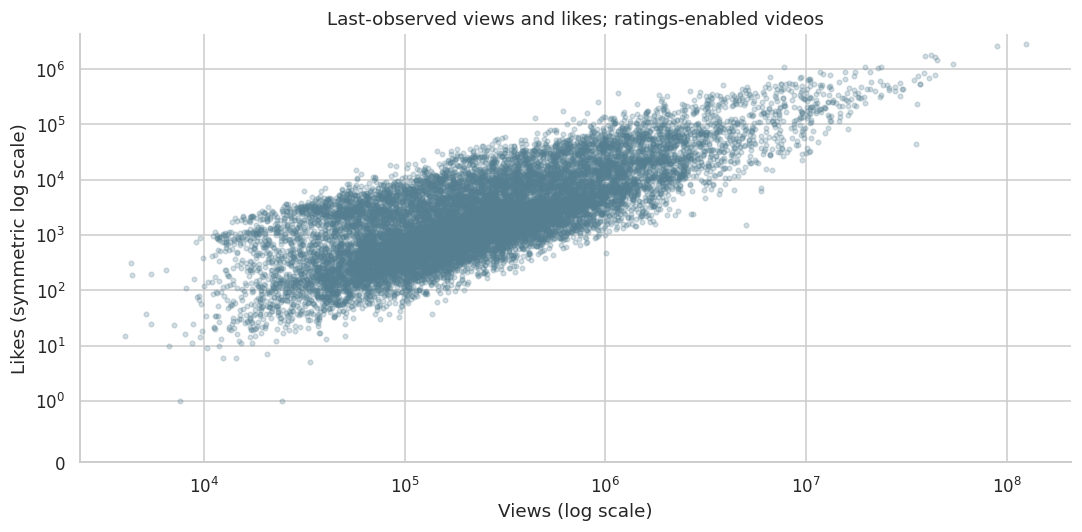

In [6]:
engagement = latest[(latest.ratings_disabled==False) & latest.views.gt(0)].dropna(subset=["views","likes"]).copy()
engagement["likes_per_1000_views"] = engagement.likes/engagement.views*1000
rho = engagement.views.corr(engagement.likes,method="spearman")
display(engagement.groupby("category").likes_per_1000_views.agg(["count","median"]).sort_values("median",ascending=False))
plt.scatter(engagement.views,engagement.likes,s=9,alpha=.25,color="#557f91")
plt.xscale("log"); plt.yscale("symlog",linthresh=1)
plt.ylim(0,engagement.likes.max()*1.5)
plt.xlabel("Views (log scale)"); plt.ylabel("Likes (symmetric log scale)")
plt.title("Last-observed views and likes; ratings-enabled videos")
plt.tight_layout(); plt.show()

**Answer.** Views and likes have a Spearman correlation of 0.722 across 15,899 eligible videos. The median is 7.54 likes per 1,000 views. Both counters accumulate over time, and a like rate is not a direct measure of viewer satisfaction.

## 4. How soon do videos first appear in the captured trending list?

First-observed delay is calculated from calendar dates, avoiding false negative delays from time-of-day differences. Negative values are listed and excluded from the delay summary. The histogram focuses on 0–30 days only for display; the printed summary uses every valid delay.

Negative delays excluded from delay summary: 0


,days
count,"16,306.000"
mean,1.310
std,1.906
min,0.000
25%,1.000
50%,1.000
75%,2.000
90%,2.000
99%,3.000
max,220.000


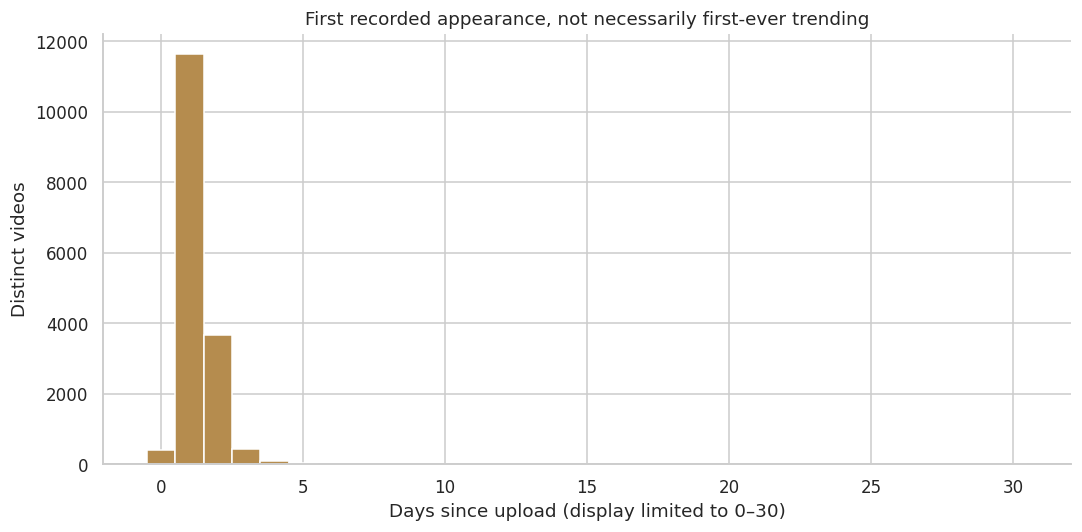

In [7]:
negative_delays = first[first.delay_days<0]
print(f"Negative delays excluded from delay summary: {len(negative_delays)}")
delays = first.loc[first.delay_days>=0,"delay_days"].dropna()
display(delays.describe(percentiles=[.25,.5,.75,.9,.99]).to_frame("days"))
within_two = delays.le(2).mean()*100
plt.hist(delays[delays<=30],bins=np.arange(-.5,31.5,1),color="#b58c4e")
plt.xlabel("Days since upload (display limited to 0–30)"); plt.ylabel("Distinct videos")
plt.title("First recorded appearance, not necessarily first-ever trending")
plt.tight_layout(); plt.show()

**Answer.** The median first-observed delay, measured in calendar days, is 1; 96.4% of valid videos are first captured within two calendar days of upload. Videos already trending before collection began are left-censored, so the first captured appearance is not guaranteed to be their first-ever appearance.

## 5. How many recorded trending days does a video have?

`nunique()` counts distinct snapshot dates per video, which avoids counting duplicated rows as extra days. These are observed appearances, not necessarily consecutive days. The beginning and end of the collection window can truncate a run.

,observed_days
count,"16,306.000"
mean,1.979
std,1.231
min,1.000
25%,1.000
50%,2.000
75%,3.000
max,9.000


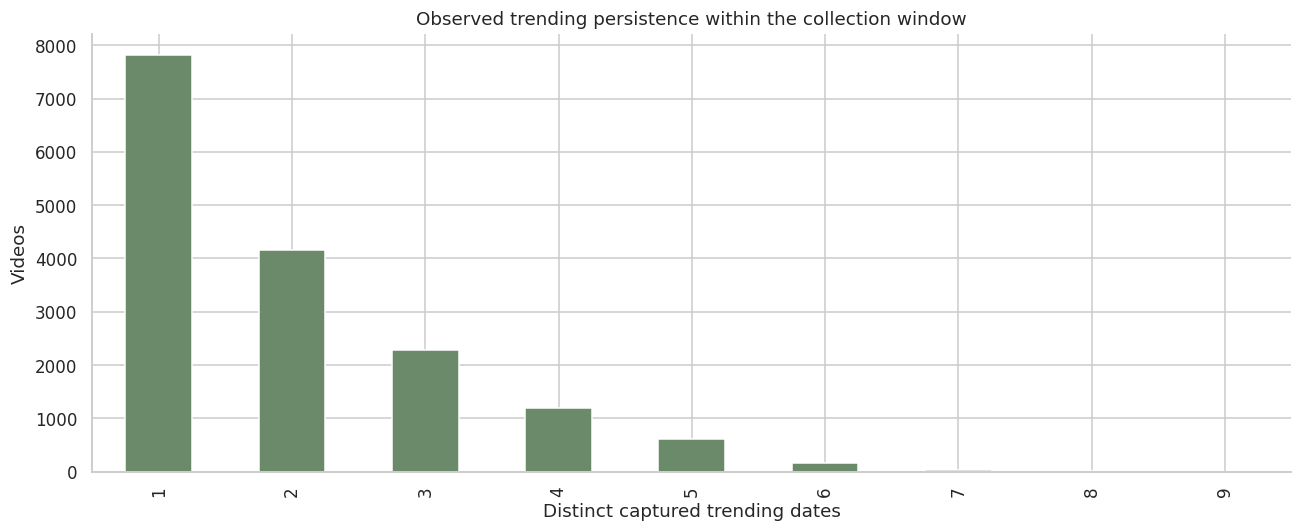

In [8]:
persistence = snapshots.groupby("video_id").trend_date.nunique().rename("observed_days")
display(persistence.describe().to_frame())
day_counts = persistence.value_counts().sort_index()
day_counts.plot.bar(color="#6a8a6a",figsize=(12,5))
plt.xlabel("Distinct captured trending dates"); plt.ylabel("Videos")
plt.title("Observed trending persistence within the collection window")
plt.tight_layout(); plt.show()

**Answer.** A video has a median of 2 captured trending days; 48.0% appear on only one recorded date. The longest observed run is 9 distinct dates, which does not prove the video trended continuously for that many days.

## Conclusion

Entertainment contributes 46.3% of distinct captured videos. The median first-observed delay is one calendar day, while 48.0% of videos appear on only one recorded trending date. These are different aspects of the captured sample, not estimates for all uploads.

Distinct-video counts, snapshot counts and cumulative engagement counters answer different questions. Treating them separately makes the category, delay and persistence results more defensible. The file describes the captured Indian trending sample rather than the full YouTube audience.
